# PS1 — Discrete Planning

Run the cells from top to bottom. Task 1 plans a path for a point robot. Task 2 builds the configuration space for a rod, and Task 3 uses that space to plan the rod's path. Task 4 repeats the search with forward-only movement. In a state $(x,y)$, $x$ is the map row and $y$ is the column.

The notebook uses the supplied course file utils.py for pose overlays and collision-map thresholding. The planning code and animation exports are defined below.

[PS1 assignment](../ps1.pdf) · [Lecture slides](#lecture)

## Task 1. Dijkstra and A* for a point robot

White cells are free and black cells are obstacles. The start and goal positions are given in the assignment.

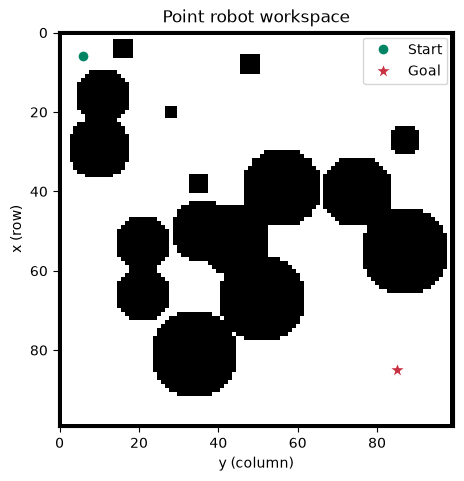

In [45]:
from importlib.util import module_from_spec, spec_from_file_location
from io import BytesIO
from pathlib import Path
from heapq import heappop, heappush
from itertools import count

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image as NotebookImage, Markdown, display
from matplotlib.colors import ListedColormap
from PIL import Image, ImageDraw, ImageFont

data_candidates = (
    Path("../data_ps1.npz"),
    Path("data_ps1.npz"),
    Path("PS/PS1/data_ps1.npz"),
)
data_path = next((p.resolve() for p in data_candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Run the notebook from PS/PS1/solution, PS/PS1, or the repository root.")

utils_spec = spec_from_file_location("ps1_utils", data_path.with_name("utils.py"))
ps1_utils = module_from_spec(utils_spec)
utils_spec.loader.exec_module(ps1_utils)

with np.load(data_path) as data:
    environment = data["environment"].astype(bool)

start_point, goal_point = (6, 6), (85, 85)
gif_dir = data_path.parent / "solution" / "outputs"

def plot_map(ax, pixels, cmap="gray_r", vmax=1):
    image = ax.imshow(pixels, cmap=cmap, vmin=0, vmax=vmax, interpolation="nearest")
    ax.set(xlabel="y (column)", ylabel="x (row)")
    return image

def mark_endpoints(ax, start, goal):
    ax.plot(start[1], start[0], "o", color="#008564", mec="white", ms=8, label="Start")
    ax.plot(goal[1], goal[0], "*", color="#c93243", mec="white", ms=12, label="Goal")

fig, ax = plt.subplots(figsize=(5, 4.7), layout="constrained")
plot_map(ax, environment)
mark_endpoints(ax, start_point, goal_point)
ax.set_title("Point robot workspace")
ax.legend(loc="upper right")
plt.show()

### 1A–B. Path search

The point robot can move one cell up, down, left, or right. Each move costs 1. A move is valid if its destination lies inside the map and is free.

Following [Lecture L02, slides 8, 13, and 14](#lecture), we remove the state with the lowest priority from the queue and examine its valid successors. If we find a cheaper path to a successor, we update its cost $g$ and its parent. When the goal is removed from the queue, we recover the path by following the parent pointers.

- **Dijkstra's algorithm** uses $g$ as its priority. **A\*** uses $g+h$. Setting $h=0$ gives Dijkstra's algorithm.
- **A\* with $L_1$** uses $h(q)=|x-x_G|+|y-y_G|$. Each move changes this estimate by at most one, and the estimate is zero at the goal. The heuristic is consistent and never overestimates the remaining cost.

When $g$ improves, we push a new entry onto the heap and skip the older entry when it comes out. Ties in $g+h$ favor smaller $h$, then earlier insertion. We count a state as **visited** when it is removed from the queue for processing, including the goal. The lecture pseudocode marks a state as discovered when it is first inserted.

In [46]:
MOVES_4 = ((-1, 0), (1, 0), (0, -1), (0, 1))

def point_neighbors(q):
    rows, cols = environment.shape
    x, y = q
    for dx, dy in MOVES_4:
        nx, ny = x + dx, y + dy
        if 0 <= nx < rows and 0 <= ny < cols and not environment[nx, ny]:
            yield (nx, ny)

def zero(q, goal):
    return 0

def l1_distance(q, goal):
    return abs(q[0] - goal[0]) + abs(q[1] - goal[1])

def restore_path(parent, q):
    path = []
    while q is not None:
        path.append(q)
        q = parent[q]
    return path[::-1]

def astar(start, goal, neighbors, heuristic):
    order = count()
    best_g = {start: 0}
    parent = {start: None}
    discovered_at = {start: 0}
    expanded = set()
    trace = []
    queue = []

    def push(q):
        g, h = best_g[q], heuristic(q, goal)
        heappush(queue, (g + h, h, next(order), g, q))

    push(start)
    while queue:
        _, h, _, g, q = heappop(queue)
        if q in expanded or g != best_g[q]:
            continue
        expanded.add(q)
        trace.append((q, g, h))
        if q == goal:
            return restore_path(parent, goal), g, trace, discovered_at, parent

        for neighbor in neighbors(q):
            candidate_g = g + 1
            if neighbor not in expanded and candidate_g < best_g.get(neighbor, np.inf):
                best_g[neighbor] = candidate_g
                parent[neighbor] = q
                discovered_at.setdefault(neighbor, len(trace))
                push(neighbor)

    return [], np.inf, trace, discovered_at, parent

def validate_plan(plan, cost, start, goal, neighbors):
    assert (plan[0], plan[-1]) == (start, goal)
    assert cost == len(plan) - 1
    assert all(b in neighbors(a) for a, b in zip(plan, plan[1:]))

def compare_searches(start, goal, neighbors, heuristics):
    results = {}
    rows = [
        "| Search | Visited states | Share of Dijkstra's count | Path cost |",
        "|:--|--:|--:|--:|",
    ]
    for name, heuristic in heuristics.items():
        result = astar(start, goal, neighbors, heuristic)
        plan, cost, trace, _, _ = result
        if plan:
            validate_plan(plan, cost, start, goal, neighbors)
        results[name] = result
        baseline = len(next(iter(results.values()))[2])
        cost_label = str(cost) if plan else "Unreachable"
        rows.append(f"| {name} | {len(trace)} | {len(trace) / baseline:.1%} | {cost_label} |")
    display(Markdown("\n".join(rows)))
    return results

point_results = compare_searches(
    start_point, goal_point, point_neighbors, {"Dijkstra": zero, "A* with L1": l1_distance}
)
assert {result[1] for result in point_results.values()} == {l1_distance(start_point, goal_point)}

| Search | Visited states | Share of Dijkstra's count | Path cost |
|:--|--:|--:|--:|
| Dijkstra | 6493 | 100.0% | 158 |
| A* with L1 | 781 | 12.0% | 158 |

Blue marks the visited cells, and the red line shows the resulting path.

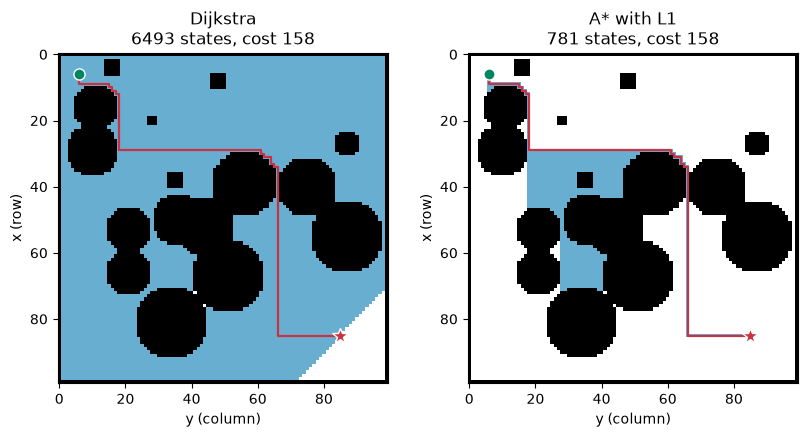

In [47]:
def plot_searches(workspace, results, start, goal, n_orientations=1):
    fig, axes = plt.subplots(
        1, len(results), figsize=(4.1 * len(results), 4.2), layout="constrained"
    )
    for ax, (name, (plan, cost, trace, _, _)) in zip(np.atleast_1d(axes), results.items()):
        plot_map(ax, workspace)
        counts = np.zeros(workspace.shape, dtype=int)
        for (x, y, *_), _, _ in trace:
            counts[x, y] += 1
        visited = np.ma.masked_equal(counts, 0)
        colors = ListedColormap(("#68aed1", "#4194bf", "#246b9b", "#103f65")[:n_orientations])
        overlay = ax.imshow(visited, cmap=colors, vmin=0.5, vmax=n_orientations + 0.5)
        xy = np.array(plan)
        ax.plot(xy[:, 1], xy[:, 0], color="#c93243", lw=1.6)
        if n_orientations > 1:
            turns = xy[1:][xy[1:, 2] != xy[:-1, 2]]
            ax.plot(turns[:, 1], turns[:, 0], "D", color="#8e2d94", mec="white",
                    ms=5, label="Rotation")
            ax.legend(loc="upper right", fontsize="small")
        mark_endpoints(ax, start, goal)
        ax.set_title(f"{name}\n{len(trace)} states, cost {cost}")
    if n_orientations > 1:
        fig.colorbar(overlay, ax=axes, ticks=range(1, n_orientations + 1),
                     shrink=0.7, label="Visited orientations per cell")
    plt.show()

plot_searches(environment, point_results, start_point, goal_point)

### Task 1 results

**Why does A* visit fewer states?** Dijkstra orders cells by cost from the start. The $L_1$ distance guides A* toward the goal. Among cells with equal cost from the start, A* explores those closer to the goal first. On this map A* visits 781 states, or **12.0%** of Dijkstra's 6,493. The reduction depends on the map and on how ties are resolved.

**What is the path cost?** Both algorithms minimize the same cost and return **158**. The $L_1$ estimate changes the search order. Here the path attains the $L_1$ lower bound with 79 moves down and 79 right.

### Point robot animations

The search GIFs show evenly spaced steps of the search. Orange marks states in the open queue, light blue marks visited states, and purple marks the current state. The blue line leads from the start to the current state. The final frame shows the resulting path in red. The path GIF shows every position from start to goal.

[task1_exploration_dijkstra.gif](outputs/task1_exploration_dijkstra.gif)

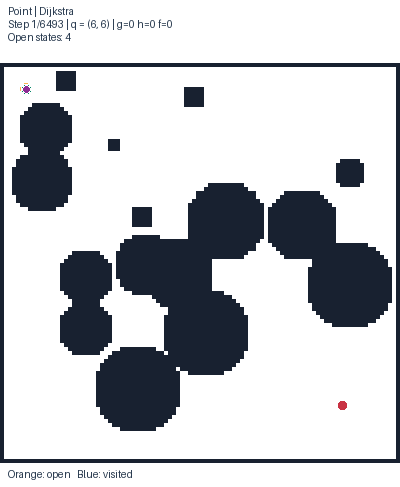

[task1_exploration_astar_l1.gif](outputs/task1_exploration_astar_l1.gif)

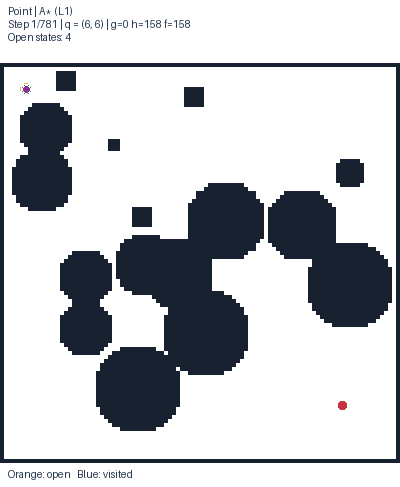

[point_solve.gif](outputs/point_solve.gif)

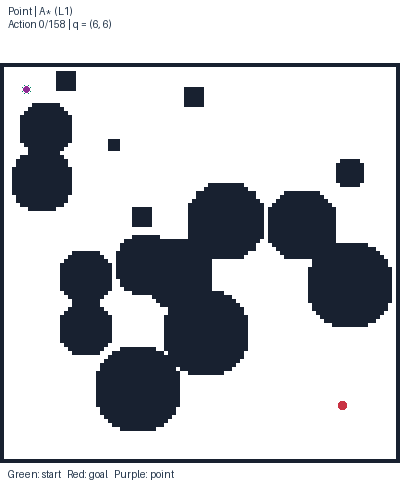

In [48]:
def gif_frame(pixels, lines, start, goal, *, path=(), current=None, legend=""):
    scale, header = 4, 63
    rows, cols = pixels.shape[:2]
    grid = Image.fromarray(pixels).resize((cols * scale, rows * scale), Image.Resampling.NEAREST)
    frame = Image.new("RGB", (grid.width, grid.height + header + 24), "#ffffff")
    frame.paste(grid, (0, header))
    draw = ImageDraw.Draw(frame)
    font = ImageFont.load_default()

    def pixel(q):
        return (q[1] * scale + scale // 2, header + q[0] * scale + scale // 2)

    if len(path) > 1:
        draw.line([pixel(q) for q in path], fill="#c93243" if current is None else "#185985", width=3)
    for state, color, radius in (
        (start, "#008564", 5), (goal, "#c93243", 5), (current, "#8e2d94", 4)
    ):
        if state is not None:
            x, y = pixel(state)
            draw.ellipse((x - radius, y - radius, x + radius, y + radius),
                         fill=color, outline="white")

    draw.multiline_text((8, 5), "\n".join(lines), fill="#24364b", font=font, spacing=3)
    draw.text((8, frame.height - 19), legend, fill="#24364b", font=font)
    return frame

def inline_animation(path):
    with Image.open(path) as gif:
        frames, delays = [], []
        for index in range(gif.n_frames):
            gif.seek(index)
            frames.append(gif.convert("RGB"))
            delays.append(gif.info["duration"])
        loop = gif.info.get("loop", 0)

    buffer = BytesIO()
    frames[0].save(buffer, format="PNG", save_all=True, append_images=frames[1:],
                   duration=delays, loop=loop)
    return buffer.getvalue()


def save_gif(frames, filename, duration):
    gif_dir.mkdir(parents=True, exist_ok=True)
    path = gif_dir / filename
    delays = [duration] * len(frames)
    delays[-1] = 1600
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=delays, loop=0)
    display(Markdown(f"[{filename}](outputs/{filename})"))
    display(NotebookImage(data=inline_animation(path), format="png"))

def save_exploration(workspace, result, start, goal, title, filename, n_orientations=None):
    plan, cost, trace, discovered_at, parent = result
    shape = workspace.shape if n_orientations is None else (*workspace.shape, n_orientations)
    discovered = np.full(shape, np.inf)
    expanded = np.full(shape, np.inf)
    for state, step in discovered_at.items():
        discovered[state] = step
    for step, (state, _, _) in enumerate(trace, start=1):
        expanded[state] = step

    base = np.where(workspace[..., None], (24, 33, 48), (255, 255, 255)).astype(np.uint8)
    frames = []
    total = len(trace)
    steps = np.linspace(1, total, min(150, total), dtype=int)
    for step in steps:
        active = (discovered <= step) & (expanded > step)
        visited = expanded <= step
        if n_orientations is None:
            open_pixels, visited_pixels = active, visited
        else:
            open_pixels, visited_pixels = active.any(axis=2), visited.any(axis=2)

        pixels = base.copy()
        pixels[visited_pixels] = (166, 210, 237)
        pixels[open_pixels] = (250, 179, 83)
        pixels[open_pixels & visited_pixels] = (152, 132, 176)

        state, g, h = trace[step - 1]
        done = step == total
        if done:
            status = f"Done | cost = {cost}" if plan else "Open states: 0 | No path"
        else:
            status = f"Open states: {active.sum()}"
        show_plan = done and bool(plan)
        frames.append(gif_frame(
            pixels, [title, f"Step {step}/{total} | q = {state} | g={g} h={h} f={g+h}", status],
            start, goal, path=plan if show_plan else restore_path(parent, state),
            current=None if show_plan else state,
            legend="Orange: open   Blue: visited   Mauve: both" if n_orientations else
                   "Orange: open   Blue: visited",
        ))
    save_gif(frames, filename, duration=70)

def save_route(workspace, plan, title, filename, rod_masks=None):
    base = np.where(workspace[..., None], (24, 33, 48), (255, 255, 255)).astype(np.uint8)
    overlay_map = workspace.astype(float)
    if rod_masks is not None:
        rx, ry = np.array(rod_masks.shape[:2]) // 2
        rows, cols = workspace.shape
        # The course helper expects the full mask window to fit inside the image.
        overlay_map = np.pad(overlay_map, ((rx, rx), (ry, ry)), constant_values=1)
    frames = []
    for step, q in enumerate(plan):
        pixels = base.copy()
        if rod_masks is not None:
            x, y, k = q
            overlay = ps1_utils.plot_environment_3d(overlay_map, rod_masks, (x + rx, y + ry, k))
            pixels[overlay[rx:rx + rows, ry:ry + cols] == 0.5] = (0, 93, 168)
        frames.append(gif_frame(
            pixels, [title, f"Action {step}/{len(plan) - 1} | q = {q}"],
            plan[0], plan[-1], path=plan[:step+1],
            current=q if rod_masks is None else None,
            legend="Green: start   Red: goal   Blue: rod" if rod_masks is not None else
                   "Green: start   Red: goal   Purple: point",
        ))
    save_gif(frames, filename, duration=60)

save_exploration(environment, point_results["Dijkstra"], start_point, goal_point,
                 "Point | Dijkstra", "task1_exploration_dijkstra.gif")
save_exploration(environment, point_results["A* with L1"], start_point, goal_point,
                 "Point | A* (L1)", "task1_exploration_astar_l1.gif")
save_route(environment, point_results["A* with L1"][0], "Point | A* (L1)", "point_solve.gif")

## Task 2. Configuration space of the rod

### 2A. Workspace and discrete orientations

Load the map and the four binary footprints of the rod. The cross marks the reference cell whose coordinates appear in the state $(x,y,\theta)$.

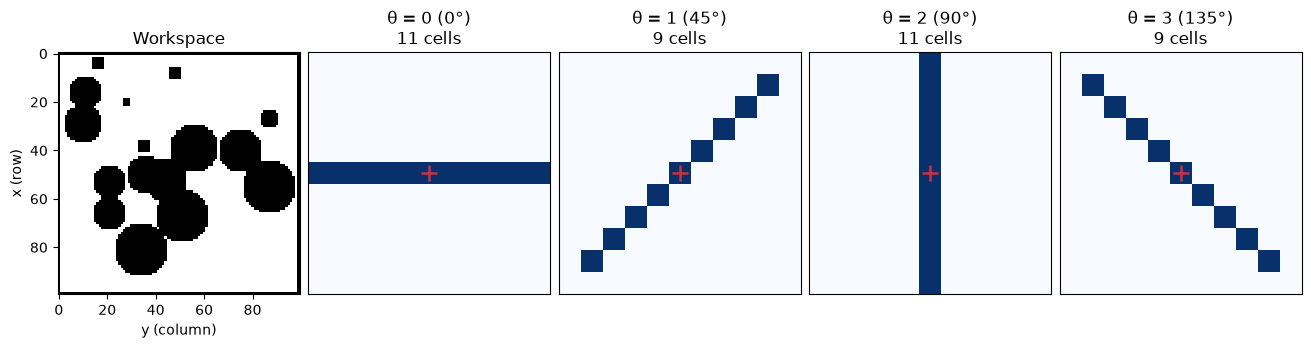

In [49]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import label
from scipy.signal import convolve2d

with np.load(data_path) as data:
    workspace = data["environment"].astype(bool)
    rod = data["rod"].astype(bool)

angles = (0, 45, 90, 135)
fig, axes = plt.subplots(1, 5, figsize=(13, 3.2), layout="constrained")
plot_map(axes[0], workspace)
axes[0].set_title("Workspace")
for k, ax in enumerate(axes[1:]):
    mask = rod[:, :, k]
    rx, ry = np.array(mask.shape) // 2
    ax.imshow(mask, cmap="Blues", interpolation="nearest")
    ax.plot(ry, rx, "+", color="#c93243", ms=12, mew=1.8)
    ax.set(title=f"θ = {k} ({angles[k]}°)\n{mask.sum()} cells", xticks=[], yticks=[])
plt.show()

assert np.array_equal(rod, rod[::-1, ::-1, :])

The rod's binary footprints are invariant under a $180^\circ$ rotation. With an angular step of $45^\circ$, the angles from $180^\circ$ through $315^\circ$ repeat the first four footprints. Intermediate angles are absent from the model. Collision checking during a rotation considers the initial and final poses. It does not check the area swept between them.

### 2B. The rod in the workspace

Use the offsets from the footprint center to find the cells occupied by the rod. For the chosen start and goal poses, verify that every occupied cell is free and within the map.

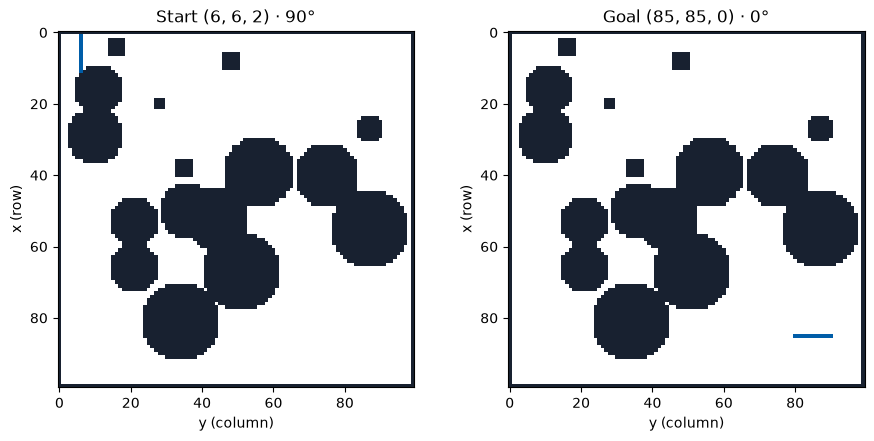

In [50]:
start_rod, goal_rod = (6, 6, 2), (85, 85, 0)
center = np.array(rod.shape[:2]) // 2
offsets = [np.argwhere(rod[:, :, k]) - center for k in range(len(angles))]
rod_colors = ListedColormap(["white", "#182130", "#005da8"])

def footprint_cells(q):
    x, y, k = q
    return (offsets[k] + (x, y)).T

def plot_pose(ax, env, q, title):
    rows, cols = footprint_cells(q)
    assert ((0 <= rows) & (rows < env.shape[0])).all()
    assert ((0 <= cols) & (cols < env.shape[1])).all()
    assert not env[rows, cols].any()
    overlay = ps1_utils.plot_environment_3d(env.astype(float), rod, q)
    pixels = np.where(overlay == 0.5, 2, env.astype(int))
    plot_map(ax, pixels, rod_colors, vmax=2)
    ax.set_title(f"{title} {q} · {angles[q[2]]}°")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.3), layout="constrained")
plot_pose(axes[0], workspace, start_rod, "Start")
plot_pose(axes[1], workspace, goal_rod, "Goal")
plt.show()

### 2C. Collision checking

Each slice holds the orientation fixed. Center the footprint at $(x,y)$ and count the occupied cells that overlap obstacles. For these symmetric footprints, two-dimensional convolution gives that count. A positive count means the configuration is blocked. Padding the map with ones treats a footprint that extends beyond the map as a collision.

To verify every slice, shift the obstacle map by each occupied offset in the footprint and take the union of the resulting collision masks.

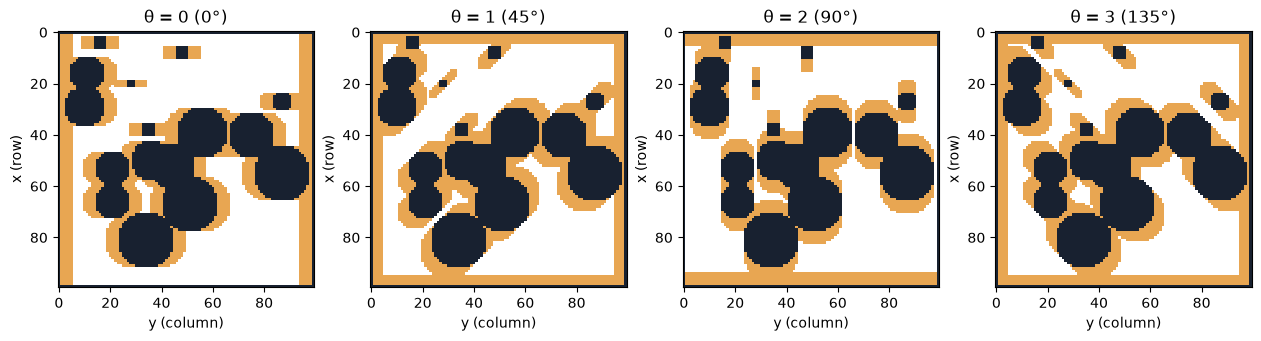

| Angle | Free configurations | Connected components |
|:--|--:|--:|
| 0° | 4677 | 2 |
| 45° | 3926 | 4 |
| 90° | 4574 | 1 |
| 135° | 3909 | 5 |

Shape: (100, 100, 4). Free configurations: 17,086 of 40,000.


In [51]:
obstacles = workspace.astype(np.uint8)
cspace = np.stack([
    ps1_utils.normalize_image(
        convolve2d(obstacles, rod[:, :, k], mode="same", boundary="fill", fillvalue=1)
    ).astype(bool)
    for k in range(len(angles))
], axis=2)

rows, cols = workspace.shape
rx, ry = center
padded = np.pad(workspace, ((rx, rx), (ry, ry)), constant_values=True)
for k, shifts in enumerate(offsets):
    collision = np.zeros_like(workspace)
    for dx, dy in shifts:
        collision |= padded[rx + dx:rx + dx + rows, ry + dy:ry + dy + cols]
    assert np.array_equal(collision, cspace[:, :, k])
assert not cspace[start_rod] and not cspace[goal_rod]

fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.8), layout="constrained")
slice_colors = ListedColormap(["white", "#e8a652", "#182130"])
rows = ["| Angle | Free configurations | Connected components |", "|:--|--:|--:|"]
for k, ax in enumerate(axes):
    blocked = cspace[:, :, k]
    pixels = np.where(workspace, 2, blocked)
    plot_map(ax, pixels, slice_colors, vmax=2)
    ax.set_title(f"θ = {k} ({angles[k]}°)")
    rows.append(f"| {angles[k]}° | {(~blocked).sum()} | {label(~blocked)[1]} |")
plt.show()
display(Markdown("\n".join(rows)))
print(f"Shape: {cspace.shape}. Free configurations: {(~cspace).sum():,} of {cspace.size:,}.")

### 2D. Comparing orientation slices

The configuration space contains $100\times100\times4=40{,}000$ configurations, of which **17,086** (42.7%) are free. Orange marks workspace cells that are free for a point but blocked as centers for the rod. At $0^\circ$, obstacles extend five cells in both directions along the column coordinate. At $90^\circ$, the same extension is along the row coordinate. The diagonal footprints extend along both coordinates, so they widen the outer border on all four sides. On this map, the diagonal slices have fewer free centers even though their footprints occupy nine cells each, compared with eleven for the horizontal and vertical footprints.

The vertical passage near column 66 is open in the $90^\circ$ slice and blocked in the $0^\circ$ slice. The table counts connected components with four-directional moves within each slice. Rotation can connect components across slices.

## Task 3. Path search for the rod

The planner takes the configuration space from Task 2 and the given start and goal poses. The plots show the workspace and the orientation slices containing the two poses.

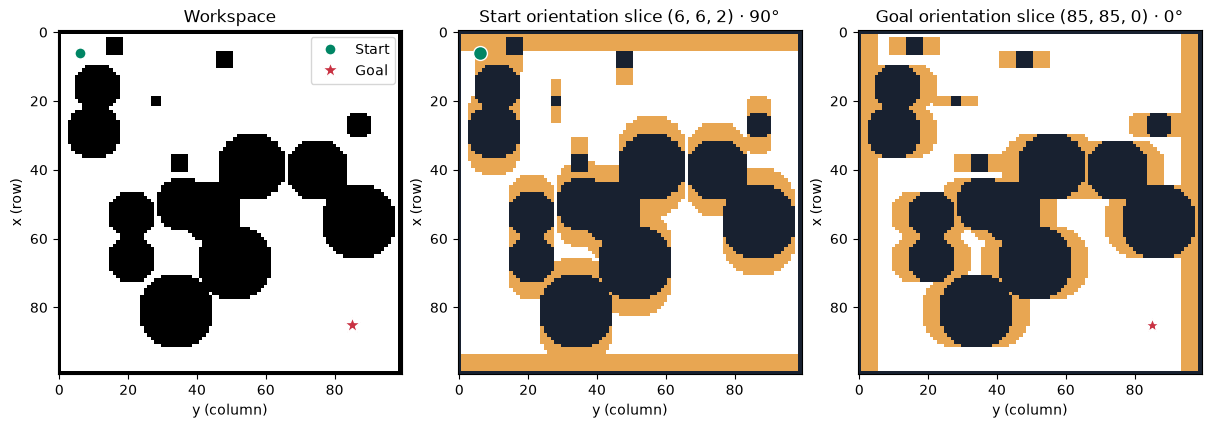

In [52]:
import matplotlib.pyplot as plt
import numpy as np

with np.load(data_path) as data:
    rod_workspace = data["environment"].astype(bool)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.0), layout="constrained")
plot_map(axes[0], rod_workspace)
mark_endpoints(axes[0], start_rod, goal_rod)
axes[0].set_title("Workspace")
axes[0].legend(loc="upper right")

for ax, q, title, marker, color in (
    (axes[1], start_rod, "Start orientation slice", "o", "#008564"),
    (axes[2], goal_rod, "Goal orientation slice", "*", "#c93243"),
):
    pixels = np.where(rod_workspace, 2, cspace[:, :, q[2]])
    plot_map(ax, pixels, slice_colors, vmax=2)
    ax.plot(q[1], q[0], marker, color=color, mec="white", ms=10)
    ax.set_title(f"{title} {q} · {angles[q[2]]}°")
plt.show()

### 3A–C. Actions and heuristics

Reuse the priority queue and path updates from Task 1 ([slides 13 and 14](#lecture)). The rod has six possible actions. Four translations preserve the orientation index, while two rotations change $\theta$ by $+1$ or $-1$ modulo 4. For example, one rotation takes the rod from $135^\circ$ to $0^\circ$ because $180^\circ$ and $0^\circ$ describe the same pose. Each action costs 1 and is valid if its destination configuration is free.

Compare $h=0$, $h=L_1(x,y)$, and $h=L_1(x,y)+d_\theta$, where
$$
d_\theta(\theta,\theta_G) =
\min\bigl(|\theta-\theta_G|,\,4-|\theta-\theta_G|\bigr).
$$

Every path to the goal requires at least $L_1$ translations and at least $d_\theta$ rotations. Each action contributes to exactly one of these counts, so their sum is an admissible lower bound on cost. The heuristic is also consistent. Each edge changes at most one term by at most one, and both terms are zero at the goal. A* therefore still finds an optimal path.

| Search | Visited states | Share of Dijkstra's count | Path cost |
|:--|--:|--:|--:|
| Dijkstra | 16323 | 100.0% | 164 |
| A* with L1 | 7720 | 47.3% | 164 |
| A* with L1 + dθ | 4572 | 28.0% | 164 |

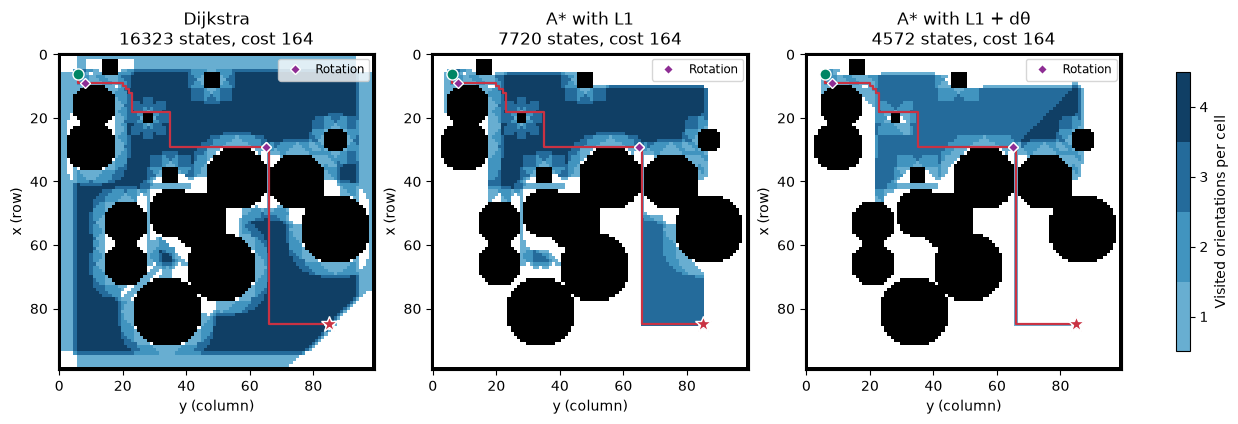

In [53]:
n_orientations = cspace.shape[2]

def rod_neighbors(q):
    rows, cols, n_angles = cspace.shape
    x, y, k = q
    for dx, dy in MOVES_4:
        nx, ny = x + dx, y + dy
        if 0 <= nx < rows and 0 <= ny < cols and not cspace[nx, ny, k]:
            yield (nx, ny, k)
    for delta in (-1, 1):
        nk = (k + delta) % n_angles
        if not cspace[x, y, nk]:
            yield (x, y, nk)

def l1_with_rotation(q, goal):
    delta = abs(q[2] - goal[2])
    return l1_distance(q, goal) + min(delta, n_orientations - delta)

rod_results = compare_searches(start_rod, goal_rod, rod_neighbors, {
    "Dijkstra": zero,
    "A* with L1": l1_distance,
    "A* with L1 + dθ": l1_with_rotation,
})
assert len({result[1] for result in rod_results.values()}) == 1
plot_searches(rod_workspace, rod_results, start_rod, goal_rod, n_orientations)

### Task 3 results

**How many states are visited, and what is the cost?** Dijkstra visits **16,323** states. A* with $L_1$ visits **7,720** (47.3% of Dijkstra's count). Including orientation reduces this to **4,572** (28.0%). All three searches return the same optimal cost of **164**.

**Why does orientation help?** The goal specifies both position and orientation. The $L_1$ heuristic assigns the same estimate to every orientation at a given position. Adding $d_\theta$ accounts for the minimum number of turns still needed. Among states with the same accumulated cost and position, A* prioritizes states that need fewer turns to match the goal. The planner still minimizes the total cost of translations and rotations.

**How does this compare with Task 1?** The rod's optimal path uses the same 158 translations and adds six turns. In Task 1, $L_1$ equals the optimal cost from the start. For the rod, even the stronger estimate starts at $158+2=160$, below the optimal cost of 164.

### Rod search and path animations

The search GIFs project configurations onto center cells. A mauve cell has
at least one orientation still in the queue and at least one already visited.
The small dark-purple dot marks the state currently being processed. The
frame header gives its full state $(x,y,\theta)$. The path GIF draws the
rod at every pose of Dijkstra's plan, including rotations in place.

[task3_exploration_dijkstra.gif](outputs/task3_exploration_dijkstra.gif)

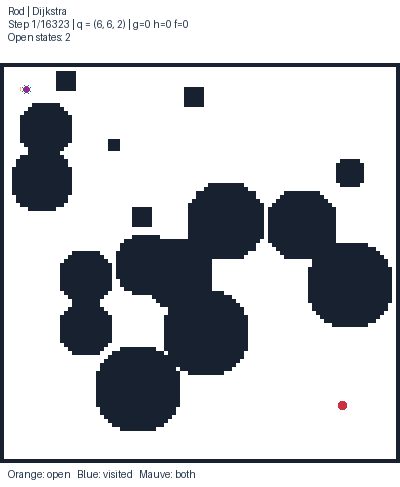

[task3_exploration_astar_l1.gif](outputs/task3_exploration_astar_l1.gif)

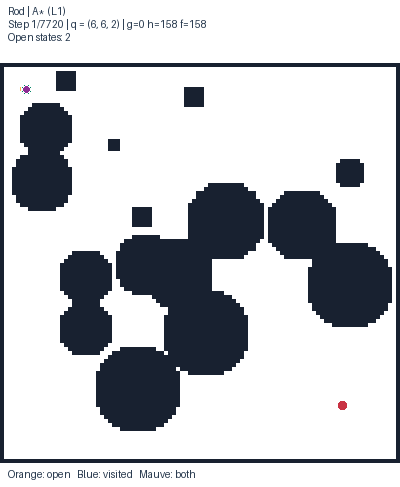

[task3_exploration_astar_l1_rot.gif](outputs/task3_exploration_astar_l1_rot.gif)

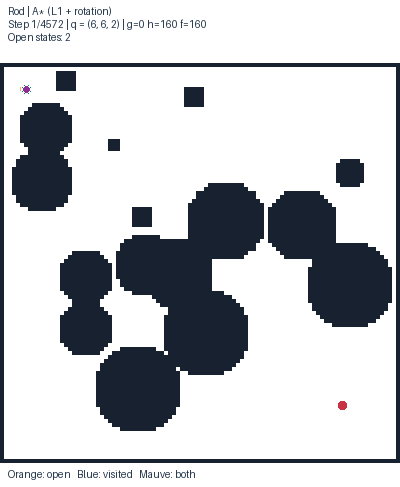

[rod_solve.gif](outputs/rod_solve.gif)

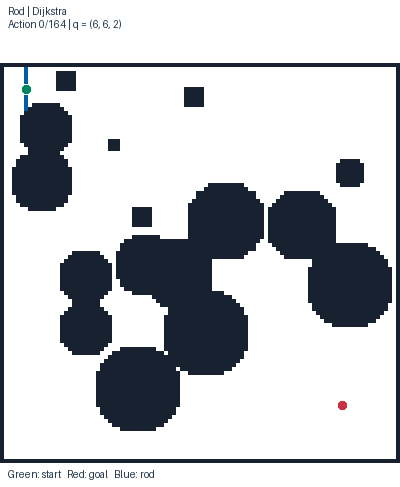

In [55]:
rod_plan = rod_results["Dijkstra"][0]

for name, title, filename in (
    ("Dijkstra", "Rod | Dijkstra", "task3_exploration_dijkstra.gif"),
    ("A* with L1", "Rod | A* (L1)", "task3_exploration_astar_l1.gif"),
    ("A* with L1 + dθ", "Rod | A* (L1 + rotation)", "task3_exploration_astar_l1_rot.gif"),
):
    save_exploration(rod_workspace, rod_results[name], start_rod, goal_rod,
                     title, filename, n_orientations=n_orientations)

save_route(rod_workspace, rod_plan, "Rod | Dijkstra", "rod_solve.gif", rod_masks=rod)

## Task 4. Can the rod reach the goal with forward-only motion?

Keep the same map and end poses as in Task 3. Give the rod a heading so that its two ends can be distinguished for motion. Heading $0^\circ$ points right and positive angles turn counterclockwise in the image, so $90^\circ$ points up. The footprints at $\theta$ and $\theta+180^\circ$ coincide, but their forward directions are opposite. The arrows below show all eight headings.

Allow the rod to turn in place and keep its starting center at (6, 6). We also test every collision-free initial heading. A turn can be blocked by an obstacle, so different initial headings can have different reachable sets.

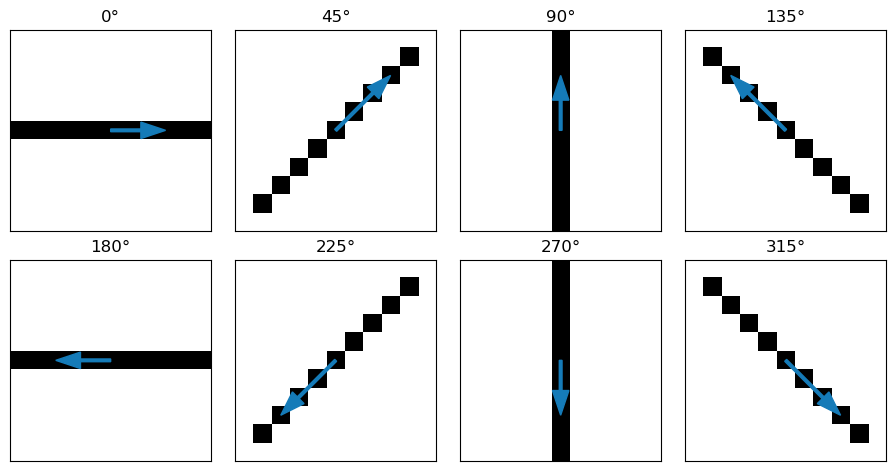

In [56]:
import matplotlib.pyplot as plt
import numpy as np

with np.load(data_path) as data:
    forward_workspace = data["environment"].astype(bool)
    forward_rod = data["rod"].astype(bool)

# Forward steps in (row, column) coordinates.
heading_steps = (
    (0, 1), (-1, 1), (-1, 0), (-1, -1),
    (0, -1), (1, -1), (1, 0), (1, 1),
)
heading_count = len(heading_steps)
forward_start, forward_goal = (6, 6, 2), (85, 85, 0)

fig, axes = plt.subplots(2, 4, figsize=(9, 4.6), layout="constrained")
for k, ax in enumerate(axes.flat):
    mask = forward_rod[:, :, k % forward_rod.shape[2]]
    row, col = np.array(mask.shape) // 2
    dx, dy = heading_steps[k]
    ax.imshow(mask, cmap="Greys", vmin=0, vmax=1)
    ax.arrow(col, row, 3 * dy, 3 * dx, color="#157bb8",
             width=0.15, head_width=0.9, length_includes_head=True)
    ax.set(title=f"{45 * k}°", xticks=[], yticks=[])
plt.show()

### Directed actions and search

Duplicate the four collision slices from Task 2 to obtain eight heading slices. A state $(x,y,k)$ has up to three actions. It can advance one grid step along heading $k$, rotate left to $(k+1)\bmod 8$, or rotate right to $(k-1)\bmod 8$. Each action costs 1, including a diagonal step. As in Task 3, collision checking is on discrete poses. We check the destination footprint and do not check intermediate poses during an action.

A forward edge goes in only one direction, so the search uses the successors of each state. Reuse Dijkstra's algorithm and compare two A* heuristics. Since a diagonal step can change both coordinates, use the Chebyshev distance $L_\infty=\max(|x-x_G|,|y-y_G|)$ as a lower bound on forward steps. Add the minimum number of $45^\circ$ rotations on the eight-heading cycle to obtain a stronger lower bound. Each action changes at most one of the two terms by at most one, so both heuristics are consistent. If the queue empties before the goal is reached, the search returns the full set of states reachable from the start.

In [57]:
forward_cspace = np.concatenate((cspace, cspace), axis=2)
assert not forward_cspace[forward_start] and not forward_cspace[forward_goal]

def forward_neighbors(q):
    x, y, k = q
    dx, dy = heading_steps[k]
    nx, ny = x + dx, y + dy
    rows, cols = forward_workspace.shape
    if 0 <= nx < rows and 0 <= ny < cols and not forward_cspace[nx, ny, k]:
        yield (nx, ny, k)
    for turn in (1, -1):
        nk = (k + turn) % heading_count
        if not forward_cspace[x, y, nk]:
            yield (x, y, nk)

def chebyshev(q, goal):
    return max(abs(q[0] - goal[0]), abs(q[1] - goal[1]))

def chebyshev_with_rotation(q, goal):
    delta = abs(q[2] - goal[2])
    return chebyshev(q, goal) + min(delta, heading_count - delta)

forward_results = compare_searches(forward_start, forward_goal, forward_neighbors, {
    "Dijkstra": zero,
    "A* with L∞": chebyshev,
    "A* with L∞ + dθ": chebyshev_with_rotation,
})

reachable = {q for q, _, _ in forward_results["Dijkstra"][2]}
assert all({q for q, _, _ in result[2]} == reachable for result in forward_results.values())
assert all(successor in reachable for q in reachable for successor in forward_neighbors(q))
reachable_centers = sorted({q[:2] for q in reachable})

start_heading_rows = [
    "| Initial heading | Reachable states | Reachable centers | Reaches goal center |",
    "|--:|--:|--:|:--|",
]
for k in range(heading_count):
    initial = (*forward_start[:2], k)
    if forward_cspace[initial]:
        start_heading_rows.append(f"| {45 * k}° | — | — | Initial pose blocked |")
        continue
    # Dijkstra exhausts the graph here. The trace records every reachable state.
    result = astar(initial, forward_goal, forward_neighbors, zero)
    centers_from_heading = {q[:2] for q, _, _ in result[2]}
    reaches_center = forward_goal[:2] in centers_from_heading
    start_heading_rows.append(
        f"| {45 * k}° | {len(result[2])} | {len(centers_from_heading)} | {'Yes' if reaches_center else 'No'} |"
    )
    assert not reaches_center
display(Markdown("\n".join(start_heading_rows)))

| Search | Visited states | Share of Dijkstra's count | Path cost |
|:--|--:|--:|--:|
| Dijkstra | 14 | 100.0% | Unreachable |
| A* with L∞ | 14 | 100.0% | Unreachable |
| A* with L∞ + dθ | 14 | 100.0% | Unreachable |

| Initial heading | Reachable states | Reachable centers | Reaches goal center |
|--:|--:|--:|:--|
| 0° | 14 | 6 | No |
| 45° | 14 | 6 | No |
| 90° | 14 | 6 | No |
| 135° | — | — | Initial pose blocked |
| 180° | 5 | 2 | No |
| 225° | 5 | 2 | No |
| 270° | 5 | 2 | No |
| 315° | — | — | Initial pose blocked |

### Where the rod gets stuck

From the stated heading of 90°, all three searches exhaust **14 configurations in six cells**. The first forward step, to (5, 6), hits the upper wall. Turning to 45° is possible. The other turn, to 135°, overlaps a nearby obstacle. After a few legal moves and turns, the rod is still trapped near the upper left of the map.

The table also shows the result for each initial heading. Six are collision-free, and none reach the goal center. The opposite vertical heading, 270°, reaches five configurations in two cells. The choice of initial heading changes which states are reachable, but the goal is unreachable in every case.

The overview marks the six reachable centers for the stated start. The close-up shows the headings available at each of those centers.

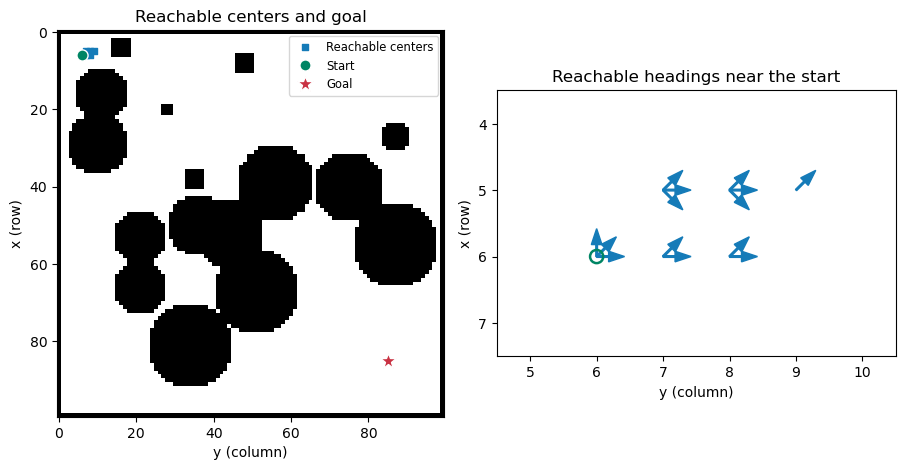

In [58]:
centers = np.asarray(reachable_centers)
fig, (overview, detail) = plt.subplots(1, 2, figsize=(9, 4.5), layout="constrained")
plot_map(overview, forward_workspace)
overview.scatter(centers[:, 1], centers[:, 0], marker="s", color="#157bb8", s=15,
                 label="Reachable centers")
mark_endpoints(overview, forward_start, forward_goal)
overview.set_title("Reachable centers and goal")
overview.legend(loc="upper right", fontsize="small")

plot_map(detail, forward_workspace)
for x, y, k in sorted(reachable):
    dx, dy = heading_steps[k]
    length = 0.42 / np.hypot(dx, dy)
    detail.arrow(y, x, dy * length, dx * length, color="#157bb8",
                 width=0.025, head_width=0.16, length_includes_head=True)
x0, y0 = centers.min(axis=0)
x1, y1 = centers.max(axis=0)
detail.set(xlim=(y0 - 1.5, y1 + 1.5), ylim=(x1 + 1.5, x0 - 1.5),
           xticks=range(y0 - 1, y1 + 2), yticks=range(x0 - 1, x1 + 2),
           title="Reachable headings near the start")
detail.scatter(forward_start[1], forward_start[0], facecolors="none",
               edgecolors="#008564", s=90, linewidths=1.8)
plt.show()

### Search animations

Each animation ends when the queue is exhausted. The blue line shows the path to the state currently being processed. There is no route animation because the goal is unreachable.

[task4_exploration_dijkstra.gif](outputs/task4_exploration_dijkstra.gif)

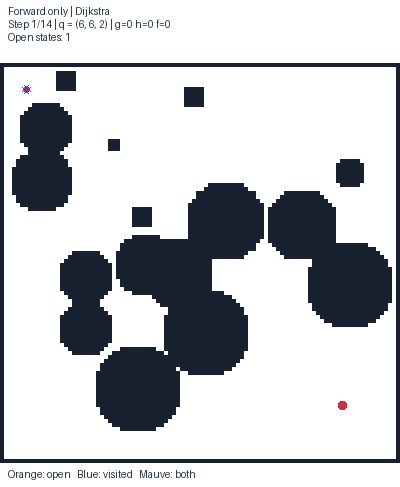

[task4_exploration_astar_linf.gif](outputs/task4_exploration_astar_linf.gif)

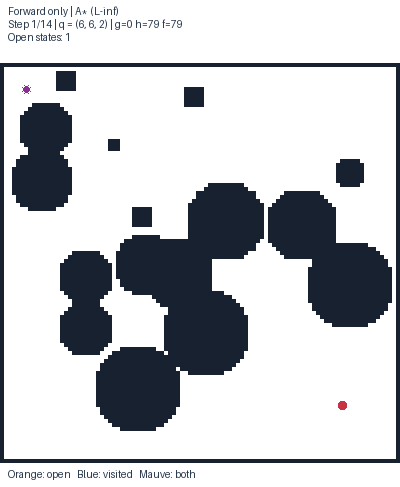

[task4_exploration_astar_linf_rot.gif](outputs/task4_exploration_astar_linf_rot.gif)

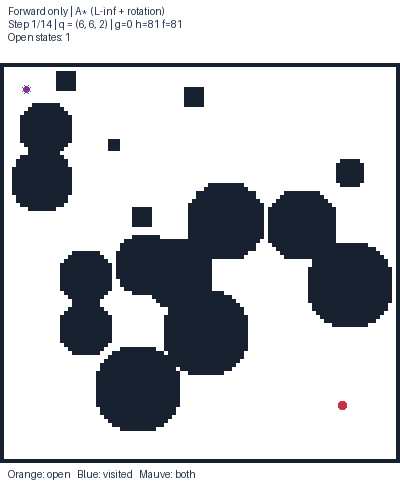

In [59]:
for name, title, filename in (
    ("Dijkstra", "Forward only | Dijkstra", "task4_exploration_dijkstra.gif"),
    ("A* with L∞", "Forward only | A* (L-inf)", "task4_exploration_astar_linf.gif"),
    ("A* with L∞ + dθ", "Forward only | A* (L-inf + rotation)", "task4_exploration_astar_linf_rot.gif"),
):
    save_exploration(forward_workspace, forward_results[name], forward_start, forward_goal,
                     title, filename, n_orientations=heading_count)

### The rod at the blocked poses

The close-up follows one branch of the search. Blue shows the current rod, and cyan marks its front tip. For each blocked action, the pale red footprint shows the proposed pose and the dark red cells show the actual overlap with obstacles. The attempted poses are illustrations and are never executed by the planner.

[task4_rod_blocked.gif](outputs/task4_rod_blocked.gif)

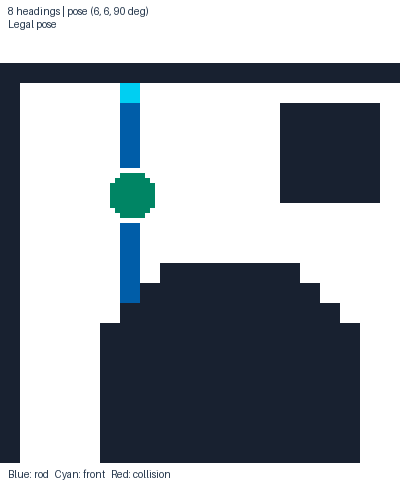

In [60]:
def rod_pose_frame(workspace, q, offsets, step_vector, title, status,
                   start, goal, *, attempt=None, crop=False):
    pixels = np.where(workspace[..., None], (24, 33, 48), (255, 255, 255)).astype(np.uint8)
    x, y, k = q
    cells = offsets[k] + (x, y)
    pixels[tuple(cells.T)] = (0, 93, 168)
    tip = cells[np.argmax(offsets[k] @ np.asarray(step_vector))]
    pixels[tuple(tip)] = (0, 207, 242)
    if attempt is not None:
        ax, ay, ak = attempt
        proposed = offsets[ak] + (ax, ay)
        inside = ((0 <= proposed) & (proposed < workspace.shape)).all(axis=1)
        rows, cols = proposed[inside].T
        hits = workspace[rows, cols]
        show = ~hits & np.all(pixels[rows, cols] == 255, axis=1)
        pixels[rows[show], cols[show]] = (249, 175, 184)
        pixels[rows[hits], cols[hits]] = (213, 32, 62)
        status += f" | {np.count_nonzero(hits) + np.count_nonzero(~inside)} blocked cells"
    legend = "Blue: rod   Cyan: front   Red: collision"
    frame = gif_frame(pixels, [title, status], start, goal, legend=legend)
    if crop:
        # Enlarge the first 20 by 20 workspace cells inside the existing frame.
        detail = frame.crop((0, 63, 80, 143)).resize((400, 400), Image.Resampling.NEAREST)
        frame.paste(detail, (0, 63))
    return frame

coarse_offsets = [np.argwhere(forward_rod[:, :, k % 4]) - np.array(forward_rod.shape[:2]) // 2
                  for k in range(heading_count)]

# Pick a terminal pose and recover the legal branch that reaches it.
dead_ends = [q for q in reachable if not list(forward_neighbors(q))]
terminal = max(dead_ends, key=lambda q: (q[1], -q[0], q[2]))
branch = restore_path(forward_results["Dijkstra"][4], terminal)

stuck_frames = []
for q in branch:
    x, y, k = q
    dx, dy = heading_steps[k]
    title = f"8 headings | pose ({x}, {y}, {45 * k} deg)"
    stuck_frames.append(rod_pose_frame(
        forward_workspace, q, coarse_offsets, heading_steps[k], title, "Legal pose",
        forward_start, forward_goal, crop=True,
    ))
    candidates = [("Forward", (x + dx, y + dy, k))]
    if q == branch[0] or q == terminal:
        candidates.extend([
            ("Turn left", (x, y, (k + 1) % heading_count)),
            ("Turn right", (x, y, (k - 1) % heading_count)),
        ])
    for action, target in candidates:
        if forward_cspace[target]:
            status = f"{action} to ({target[0]}, {target[1]}, {45 * target[2]} deg)"
            stuck_frames.append(rod_pose_frame(
                forward_workspace, q, coarse_offsets, heading_steps[k], title, status,
                forward_start, forward_goal, attempt=target, crop=True,
            ))

save_gif(stuck_frames, "task4_rod_blocked.gif", duration=1100)

### A finer discretization that admits a route

On this integer grid, adding a heading requires a way to move along it. Use the 16 shortest integer direction vectors with components of magnitude at most 2. Keep the eight original directions and insert slopes such as 1:2 and 2:1. The largest angle between adjacent headings falls from 45° to about 26.6°. A step along a new heading can cross up to two rows or columns.

Keep the supplied footprints for the original headings. For each new heading, rasterize a centered line segment by sampling it and rounding sample positions to cells. Its half-length is the largest center-to-tip distance among the supplied footprints. The robot turns between neighboring headings. A new forward move checks the destination and the grid cells surrounding the center's midpoint, so a two-cell step cannot simply skip the obstacle check between endpoints. This remains a discrete collision model.

Run Dijkstra twice with these same 16 footprints and turns. First, allow forward steps only along the original eight headings. Then enable forward steps along the new directions as well. In both runs, keep the original start and goal centers and their 90° and 0° headings. All actions cost one within each model, so the cost counts actions rather than travel distance.

In [61]:
from math import gcd

from scipy.ndimage import binary_dilation

def heading_angle(step):
    dx, dy = step
    return np.arctan2(-dx, dy) % (2 * np.pi)

fine_steps = sorted(
    ((dx, dy) for dx in range(-2, 3) for dy in range(-2, 3) if gcd(dx, dy) == 1),
    key=heading_angle,
)
assert len(fine_steps) == 16
half_length = max(np.linalg.norm(offsets, axis=1).max() for offsets in coarse_offsets)
fine_offsets = []
for step in fine_steps:
    if step in heading_steps:
        offsets = coarse_offsets[heading_steps.index(step)]
    else:
        unit = np.asarray(step) / np.linalg.norm(step)
        samples = np.linspace(-half_length, half_length, 201)[:, None] * unit
        offsets = np.unique(np.rint(samples).astype(int), axis=0)
    fine_offsets.append(offsets)

def collision_slice(workspace, offsets):
    radius = np.abs(offsets).max(axis=0)
    mask = np.zeros(tuple(2 * radius + 1), dtype=bool)
    mask[tuple((offsets + radius).T)] = True
    return binary_dilation(workspace, structure=mask, border_value=1)

fine_cspace = np.stack([collision_slice(forward_workspace, offsets) for offsets in fine_offsets], axis=2)
for k, step in enumerate(heading_steps):
    assert np.array_equal(forward_cspace[:, :, k], fine_cspace[:, :, fine_steps.index(step)])

fine_start = (*forward_start[:2], fine_steps.index(heading_steps[forward_start[2]]))
fine_goal = (*forward_goal[:2], fine_steps.index(heading_steps[forward_goal[2]]))

def fine_neighbors(q, allow_new_steps=True):
    x, y, k = q
    dx, dy = fine_steps[k]
    nx, ny = x + dx, y + dy
    rows, cols = forward_workspace.shape
    if (allow_new_steps or (dx, dy) in heading_steps) and 0 <= nx < rows and 0 <= ny < cols:
        if not fine_cspace[nx, ny, k]:
            if max(abs(dx), abs(dy)) == 1:
                yield (nx, ny, k)
            else:
                mid_rows = {x + dx // 2, x + (dx + 1) // 2}
                mid_cols = {y + dy // 2, y + (dy + 1) // 2}
                if all(not fine_cspace[i, j, k] for i in mid_rows for j in mid_cols):
                    yield (nx, ny, k)
    for turn in (1, -1):
        nk = (k + turn) % len(fine_steps)
        if not fine_cspace[x, y, nk]:
            yield (x, y, nk)

turns_only = astar(fine_start, fine_goal, lambda q: fine_neighbors(q, False), zero)
fine_result = astar(fine_start, fine_goal, fine_neighbors, zero)
fine_plan, fine_cost, fine_trace, _, _ = fine_result
validate_plan(fine_plan, fine_cost, fine_start, fine_goal, fine_neighbors)
assert not turns_only[0] and fine_cost == 88
fine_turns = sum(a[2] != b[2] for a, b in zip(fine_plan, fine_plan[1:]))
display(Markdown("\n".join([
    "| Heading model | Visited states | Path cost |", "|:--|--:|--:|",
    f"| 8 headings | {len(reachable):,} | Unreachable |",
    f"| 16 headings, original forward directions | {len(turns_only[2]):,} | Unreachable |",
    f"| 16 headings, all forward directions | {len(fine_trace):,} | {fine_cost} |",
])))
print(f"Route: {fine_cost - fine_turns} forward steps and {fine_turns} turns.")

Route: 72 forward steps and 16 turns.


| Heading model | Visited states | Path cost |
|:--|--:|--:|
| 8 headings | 14 | Unreachable |
| 16 headings, original forward directions | 27 | Unreachable |
| 16 headings, all forward directions | 52,321 | 88 |

The finer model reaches the goal in **88 actions**. Its first translation is from (6, 6) to (5, 8), after turning to about 26.6°. That angle and its forward direction are absent from the eight-heading model. With 16 headings but only the original eight forward directions, the search still exhausts the reachable states without reaching the goal.

This shows that the coarse discretization can make a route impossible in the model. The successful experiment changes both the available angles and the forward directions on the grid. Its collision checks apply to the sampled poses described above.

[task4_rod_fine_route.gif](outputs/task4_rod_fine_route.gif)

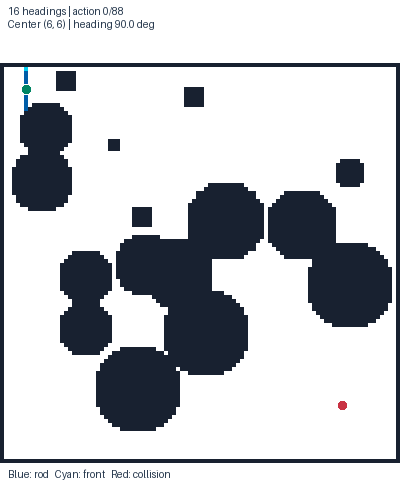

In [62]:
fine_frames = []
for index, q in enumerate(fine_plan):
    angle = np.degrees(heading_angle(fine_steps[q[2]]))
    fine_frames.append(rod_pose_frame(
        forward_workspace, q, fine_offsets, fine_steps[q[2]],
        f"16 headings | action {index}/{fine_cost}",
        f"Center ({q[0]}, {q[1]}) | heading {angle:.1f} deg",
        fine_start, fine_goal,
    ))
save_gif(fine_frames, "task4_rod_fine_route.gif", duration=115)

<a id="lecture"></a>

### Lecture reference

Gonzalo Ferrer, *L02: Discrete Planning*, Skoltech, October 28, 2026. Slide 8 covers general forward search, slide 13 presents Dijkstra's algorithm, and slides 14–15 cover A* and heuristic selection.